
# Homework 4: Machine Learning Classification

**Environmental Data Science – OEAS 805**

This homework uses the wine dataset from scikit-learn to build and evaluate a Multi-Layer Perceptron (MLP) classification model. The goal is to compare different neural network structures and predict the classes of unknown wine samples.


In [1]:

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import metrics
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Load the wine dataset
wine = load_wine()

# Convert the feature data into a pandas DataFrame
data = pd.DataFrame(wine.data, columns=wine.feature_names)

# Add the target variable
data["target"] = wine.target

# Display the first five rows
data.head()


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



## Initial Data Exploration

Before building the classification model, I first examine the dataset to understand its structure, check for missing values and duplicates, and explore the distribution of the target classes.


In [2]:

# Check dataset dimensions
print("Dataset shape:", data.shape)

# Check column names and data types
print("\nDataset information:")
data.info()

# Check missing values
print("\nMissing values:")
print(data.isnull().sum())

# Check duplicate observations
print("\nDuplicate rows:", data.duplicated().sum())

# Check the number of observations in each target class
print("\nTarget class distribution:")
print(data["target"].value_counts().sort_index())

# Summary statistics of the dataset
data.describe()


Dataset shape: (178, 14)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                     

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000



### Initial Data Exploration Results

The dataset contains 178 observations, 13 numerical features, and three wine classes. There are no missing values or duplicate rows, so additional data cleaning is not needed. Class 1 has the most observations (71), followed by Class 0 (59) and Class 2 (48). Since the features have different numerical ranges, I will standardize them before building the classification model.


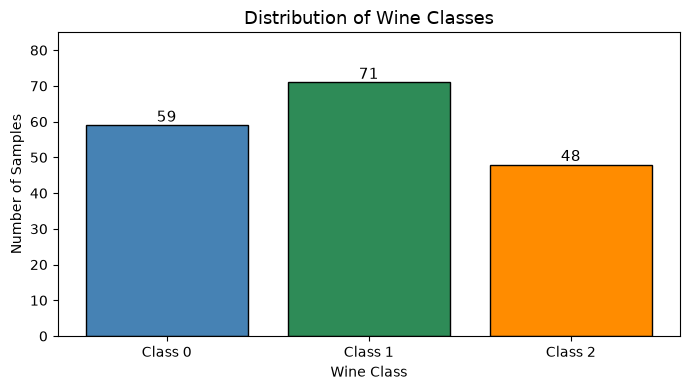

In [3]:

# Visualize the distribution of wine classes
class_counts = data["target"].value_counts().sort_index()

plt.figure(figsize=(7, 4))

bars = plt.bar(
    ["Class 0", "Class 1", "Class 2"],
    class_counts.values,
    color=["steelblue", "seagreen", "darkorange"],
    edgecolor="black"
)

# Add observation counts above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(int(bar.get_height())),
        ha="center",
        fontsize=11
    )

plt.title("Distribution of Wine Classes", fontsize=13)
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.ylim(0, 85)
plt.tight_layout()
plt.show()



### Interpretation

The bar chart shows the distribution of the three wine classes. Class 1 has the highest number of samples (71), followed by Class 0 (59) and Class 2 (48). Although the classes are not equally distributed, all three classes have enough observations to be included in the classification analysis.



## Part 1: Model Construction

In this section, I use the wine dataset to build a Multi-Layer Perceptron (MLP) classification model. I split the dataset into training and testing sets, standardize the features, and evaluate the initial model accuracy.


In [4]:

# Separate the features and target variable
X = data.drop(columns=["target"])
y = data["target"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Check the number of training and testing samples
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Build the initial MLPClassifier model
mlp = MLPClassifier(
    hidden_layer_sizes=(10,),
    max_iter=2000,
    random_state=42
)

# Train the model
mlp.fit(X_train_scaled, y_train)

# Predict wine classes
y_pred = mlp.predict(X_test_scaled)

# Calculate model accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)

print("Initial MLPClassifier accuracy:", round(accuracy, 4))


Training samples: 142
Testing samples: 36
Initial MLPClassifier accuracy: 1.0



### Part 1 Results

The initial MLPClassifier model used one hidden layer with 10 neurons. The dataset was divided into 142 training samples and 36 testing samples. The model achieved an accuracy of 1.00 (100%) on the test data, meaning all 36 samples were correctly classified. Although the initial result is very good, I will explore other combinations of hidden layers and neurons in Part 2 to compare model performance.



## Part 2: Exploring Hyperparameter Space

In this section, I compare different combinations of hidden layers and neurons to find which neural network structure gives the best classification accuracy. I use cross-validation on the training data to compare the models and avoid using the test data for hyperparameter selection.


In [7]:

# Import cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# Define the number of layers and neurons to test
layers_list = [1, 2, 3, 4]
neurons_list = [5, 10, 15, 20]

# Set up five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store model results
results = []

# Test different combinations of layers and neurons
for layers in layers_list:
    for neurons in neurons_list:

        hidden_structure = tuple([neurons] * layers)

        # Create a pipeline to standardize and train the model
        model = make_pipeline(
            StandardScaler(),
            MLPClassifier(
                hidden_layer_sizes=hidden_structure,
                max_iter=1000,
                random_state=42
            )
        )

        # Calculate cross-validation accuracy
        scores = cross_val_score(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring="accuracy"
        )

        # Save the results
        results.append({
            "Layers": layers,
            "Neurons": neurons,
            "Mean Accuracy": scores.mean(),
            "Std Accuracy": scores.std()
        })

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

# Display results from highest to lowest accuracy
results_df.sort_values(
    by="Mean Accuracy",
    ascending=False
).round(4)


/opt/anaconda3/envs/hw4_env/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/hw4_env/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Layers,Neurons,Mean Accuracy,Std Accuracy
10,3,15,0.9862,0.0276
14,4,15,0.9862,0.0276
15,4,20,0.9860,0.0172
6,2,15,0.9793,0.0414
4,2,5,0.9791,0.0277
2,1,15,0.9653,0.0378
3,1,20,0.9650,0.0378
7,2,20,0.9650,0.0314
11,3,20,0.9650,0.0314
13,4,10,0.9584,0.0402



### Comparison of Hidden Layers and Neurons

The following heatmap shows the mean cross-validation accuracy for different combinations of hidden layers and neurons. This helps identify which neural network structures perform better.


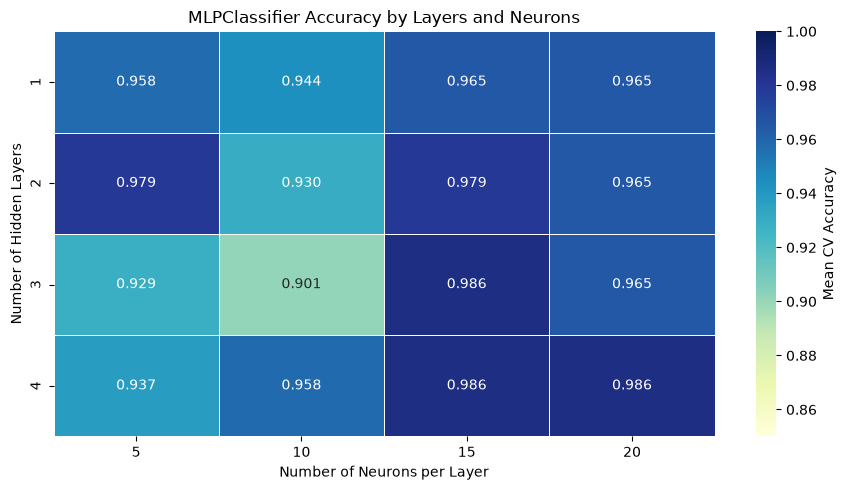

In [8]:

# Create a table for the accuracy heatmap
accuracy_table = results_df.pivot(
    index="Layers",
    columns="Neurons",
    values="Mean Accuracy"
)

# Plot the heatmap
plt.figure(figsize=(9, 5))

import seaborn as sns

sns.heatmap(
    accuracy_table,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0.85,
    vmax=1.0,
    cbar_kws={"label": "Mean CV Accuracy"}
)

plt.title("MLPClassifier Accuracy by Layers and Neurons")
plt.xlabel("Number of Neurons per Layer")
plt.ylabel("Number of Hidden Layers")
plt.tight_layout()
plt.show()



### Interpretation

The results show that most combinations of hidden layers and neurons performed well, with all mean accuracy scores above 0.90. The highest accuracy (0.9862) was achieved using three or four hidden layers with 15 neurons per layer. Since both models have the same accuracy, the three-layer model may be a better choice because it has a simpler structure. However, I will also compare the confusion matrices, precision, recall, and F1-scores before making the final decision.



### Classification Performance of Models with Accuracy Above 0.90

I evaluate the models with mean cross-validation accuracy above 0.90 using confusion matrices, precision, recall, and F1-scores for each wine class. I use cross-validated predictions from the training dataset so that the test dataset remains separate for final evaluation.


In [9]:

# Import tools for cross-validated predictions
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_fscore_support

# Select models with mean CV accuracy above 0.90
qualified_models = results_df[
    results_df["Mean Accuracy"] > 0.90
].copy()

# Store classification metrics
evaluation_results = []
confusion_matrices = {}

for _, row in qualified_models.iterrows():

    layers = int(row["Layers"])
    neurons = int(row["Neurons"])

    structure = tuple([neurons] * layers)

    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=structure,
            max_iter=1000,
            random_state=42
        )
    )

    # Obtain predictions using cross-validation
    predictions = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv
    )

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1, 2]
    )

    confusion_matrices[(layers, neurons)] = cm

    # Calculate metrics for each target class
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_train,
            predictions,
            labels=[0, 1, 2],
            zero_division=0
        )
    )

    for class_id in range(3):
        evaluation_results.append({
            "Layers": layers,
            "Neurons": neurons,
            "Class": class_id,
            "Precision": precision[class_id],
            "Recall": recall[class_id],
            "F1-score": f1[class_id],
            "Support": support[class_id]
        })

# Display class-specific results for all models
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(3))


/opt/anaconda3/envs/hw4_env/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/hw4_env/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Layers,Neurons,Class,Precision,Recall,F1-score,Support
0,1,5,0,0.922,1.000,0.959,47
1,1,5,1,1.000,0.895,0.944,57
2,1,5,2,0.950,1.000,0.974,38
3,1,10,0,0.958,0.979,0.968,47
4,1,10,1,0.980,0.877,0.926,57
5,1,10,2,0.884,1.000,0.938,38
6,1,15,0,0.959,1.000,0.979,47
7,1,15,1,1.000,0.912,0.954,57
8,1,15,2,0.927,1.000,0.962,38
9,1,20,0,0.959,1.000,0.979,47


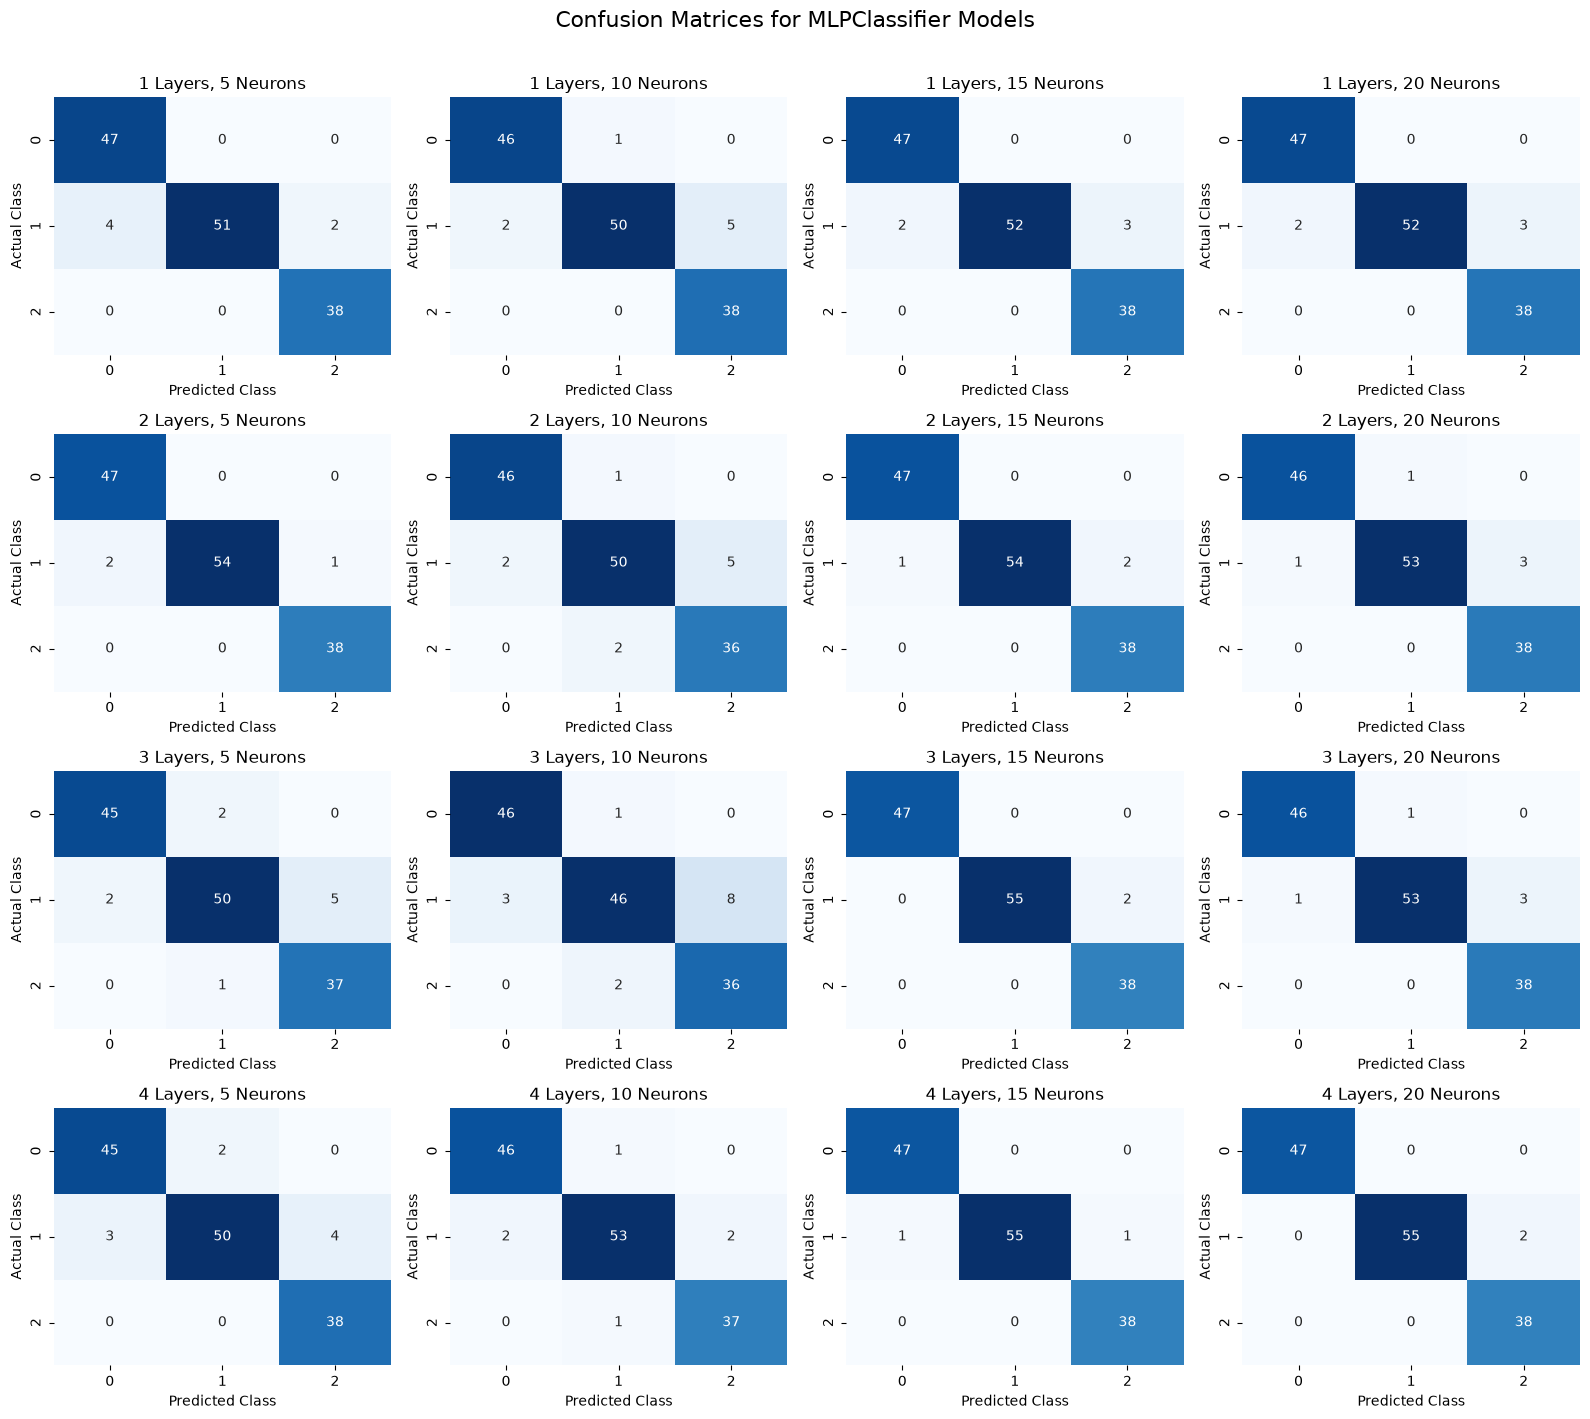

In [10]:

# Plot confusion matrices for all qualifying models
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for ax, ((layers, neurons), cm) in zip(
    axes.flat,
    confusion_matrices.items()
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=[0, 1, 2],
        yticklabels=[0, 1, 2]
    )

    ax.set_title(f"{layers} Layers, {neurons} Neurons")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrices for MLPClassifier Models",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()



### Interpretation of Classification Performance

All 16 model combinations achieved mean cross-validation accuracy above 0.90. The models with three and four hidden layers and 15 neurons per layer had the highest mean accuracy (0.9862).

For the three-layer, 15-neuron model, Class 0 had perfect precision, recall, and F1-score. Class 1 had slightly lower recall (0.965), while Class 2 had perfect recall but lower precision (0.950). This suggests that the model classified most observations correctly, although there were a few errors between classes.

The four-layer model also performed very well, but it did not improve the overall mean accuracy. Therefore, I prefer the three-layer, 15-neuron model because it has a simpler structure while maintaining high classification performance.



### Final Model Selection and Test Evaluation

Based on the cross-validation results and class-specific performance, I selected the MLPClassifier with three hidden layers and 15 neurons per layer. I now evaluate this selected model using the separate test dataset.


Final Model: (15, 15, 15)
Final Test Accuracy: 0.9722

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



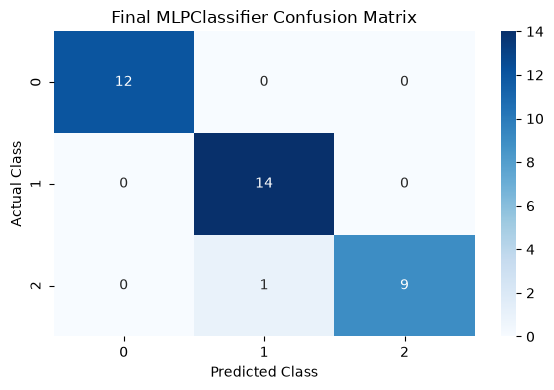

In [11]:

# Train the selected model
final_model = MLPClassifier(
    hidden_layer_sizes=(15, 15, 15),
    max_iter=1000,
    random_state=42
)

final_model.fit(X_train_scaled, y_train)

# Predict the test data
final_predictions = final_model.predict(X_test_scaled)

# Calculate final test accuracy
final_accuracy = accuracy_score(y_test, final_predictions)

print("Final Model: (15, 15, 15)")
print("Final Test Accuracy:", round(final_accuracy, 4))

# Display class-specific performance
print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

# Display final confusion matrix
final_cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title("Final MLPClassifier Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()



### Final Model Results

The selected MLPClassifier with three hidden layers and 15 neurons per layer achieved a test accuracy of 0.9722 (97.22%). Out of 36 test samples, 35 were correctly classified. The model correctly predicted all samples from Class 0 and Class 1, but one sample from Class 2 was incorrectly classified as Class 1.

The classification report also shows good precision, recall, and F1-scores across all three classes. Overall, the model performed well on the test data, suggesting that the selected combination of hidden layers and neurons is suitable for predicting wine classes.



## Part 3: Classification of Unknown Wine Samples

In this section, I use the selected MLPClassifier model to predict the classes of unknown wine samples. I also calculate the probability of each sample belonging to the three wine classes.


In [13]:

# Load the unknown wine dataset
unknown_wine = pd.read_csv("../data/unknown_wine.csv")

# Check the dataset
print("Unknown wine dataset shape:", unknown_wine.shape)

display(unknown_wine.head())

print("\nColumn names:")
print(unknown_wine.columns.tolist())


Unknown wine dataset shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.20,1.75,2.44,15.3,115.3,3.17,3.35,0.33,2.05,6.52,1.04,3.09,1363.0,0
1,13.46,3.45,2.17,18.4,89.8,2.47,2.67,0.27,1.54,4.50,0.95,2.99,1089.5,0
2,13.74,1.79,2.57,15.6,111.8,3.34,3.33,0.31,1.65,7.16,1.15,3.06,1243.6,0
3,14.24,3.68,2.43,17.9,109.5,2.91,2.82,0.30,1.54,5.54,0.92,3.28,1152.1,0
4,13.82,1.63,2.26,16.9,98.6,2.43,2.59,0.27,1.69,5.00,1.09,2.97,1179.1,0



Column names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']



### Predicting Wine Classes and Probabilities

I use the selected MLPClassifier model to predict the wine classes and calculate the probability of each sample belonging to Class 0, Class 1, and Class 2. I exclude the target column from the input features and apply the same standardization used during model training.


In [14]:

# Select the same 13 features used for training
unknown_features = unknown_wine[X.columns]

# Standardize using the original training scaler
unknown_scaled = scaler.transform(unknown_features)

# Predict wine classes
unknown_predictions = final_model.predict(unknown_scaled)

# Calculate probabilities for all three classes
unknown_probabilities = final_model.predict_proba(unknown_scaled)

# Create a results table
prediction_results = pd.DataFrame({
    "Predicted Class": unknown_predictions,
    "Probability Class 0": unknown_probabilities[:, 0],
    "Probability Class 1": unknown_probabilities[:, 1],
    "Probability Class 2": unknown_probabilities[:, 2]
})

# Display the first 10 predictions
display(prediction_results.head(10).round(4))

print("Total samples predicted:", len(prediction_results))
print("\nPredicted class distribution:")
print(prediction_results["Predicted Class"].value_counts().sort_index())


,Predicted Class,Probability Class 0,Probability Class 1,Probability Class 2
0,0,0.9999,0.0000,0.0000
1,0,0.9890,0.0075,0.0035
2,0,1.0000,0.0000,0.0000
3,0,0.9988,0.0004,0.0008
4,0,0.9988,0.0009,0.0003
5,0,0.9964,0.0025,0.0011
6,0,0.9955,0.0041,0.0004
7,0,0.9993,0.0004,0.0003
8,0,0.9996,0.0003,0.0002
9,0,0.9920,0.0052,0.0027


Total samples predicted: 178

Predicted class distribution:
Predicted Class
0    59
1    71
2    48
Name: count, dtype: int64


In [15]:

# Compare the unknown dataset with the original wine dataset
print("Same number of rows:", len(unknown_wine) == len(data))

print("Features identical to original dataset:",
      np.allclose(
          unknown_wine[X.columns].to_numpy(),
          data[X.columns].to_numpy()
      ))

print("Target labels identical:",
      np.array_equal(
          unknown_wine["target"].to_numpy(),
          data["target"].to_numpy()
      ))

# Compare predictions with the CSV target labels
print("Prediction agreement with CSV labels:",
      round(accuracy_score(
          unknown_wine["target"],
          unknown_predictions
      ), 4))


Same number of rows: True
Features identical to original dataset: False
Target labels identical: True
Prediction agreement with CSV labels: 1.0


In [19]:

# Display probabilities for all 178 samples
with pd.option_context("display.max_rows", None):
    display(prediction_results.round(4))


,Predicted Class,Probability Class 0,Probability Class 1,Probability Class 2,Highest Probability
0,0,0.9999,0.0000,0.0000,0.9999
1,0,0.9890,0.0075,0.0035,0.9890
2,0,1.0000,0.0000,0.0000,1.0000
3,0,0.9988,0.0004,0.0008,0.9988
4,0,0.9988,0.0009,0.0003,0.9988
5,0,0.9964,0.0025,0.0011,0.9964
6,0,0.9955,0.0041,0.0004,0.9955
7,0,0.9993,0.0004,0.0003,0.9993
8,0,0.9996,0.0003,0.0002,0.9996
9,0,0.9920,0.0052,0.0027,0.9920


In [17]:

# Find the highest predicted probability for each sample
prediction_results["Highest Probability"] = unknown_probabilities.max(axis=1)

print("Average prediction confidence:",
      round(prediction_results["Highest Probability"].mean(), 4))

print("Lowest prediction confidence:",
      round(prediction_results["Highest Probability"].min(), 4))

print("Samples with confidence below 0.90:",
      (prediction_results["Highest Probability"] < 0.90).sum())

# Show the five least confident predictions
display(
    prediction_results.sort_values(
        "Highest Probability"
    ).head(5).round(4)
)


Average prediction confidence: 0.9917
Lowest prediction confidence: 0.6304
Samples with confidence below 0.90: 3


,Predicted Class,Probability Class 0,Probability Class 1,Probability Class 2,Highest Probability
80,1,0.3644,0.6304,0.0052,0.6304
139,2,0.0029,0.2260,0.7712,0.7712
92,1,0.0290,0.8133,0.1577,0.8133
98,1,0.0954,0.9033,0.0014,0.9033
126,1,0.0263,0.9251,0.0487,0.9251



### Interpretation of Unknown Wine Predictions

The selected MLPClassifier predicted 59 samples as Class 0, 71 as Class 1, and 48 as Class 2. All 178 predictions matched the target labels available in the unknown wine dataset.

The average prediction confidence was 0.9917 (99.17%), which shows that the model was highly confident for most samples. Only three samples had a confidence level below 0.90. For example, sample 80 was predicted as Class 1 with a probability of 0.6304, while the probability for Class 0 was 0.3644. This indicates some uncertainty in classifying this sample.

Overall, the model performed well in predicting the wine classes. However, since the unknown wine dataset has the same target label sequence as the original wine dataset, this result should not be considered an independent test of model accuracy.
